<a href="https://colab.research.google.com/github/fitraadhim/244107020089_MachineLearning/blob/main/JS09/tugas1JS09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Tahap 1: Persiapan Library & Pemuatan Dataset
Pada tahap ini, kita memuat library Python yang dibutuhkan seperti Pandas, NumPy, Sklearn, serta mengimpor dataset `voice.csv` untuk dianalisis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Muat dataset voice.csv
df = pd.read_csv('voice.csv')

# Tampilkan 5 baris pertama
print("5 Data Teratas:")
display(df.head())

# Informasi umum dataset
print("\nInformasi Dataset:")
df.info()

5 Data Teratas:


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male



Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     

## Tahap 2: Pra-pemrosesan Data (Preprocessing)
Kita mengecek nilai yang hilang (*missing values*) serta mengubah variabel target kategorikal (`label`: male/female) menjadi format numerik (0 dan 1) agar dapat diproses oleh algoritma kNN.

In [2]:
# Cek missing values
print("Jumlah Missing Values:")
print(df.isnull().sum())

# Ubah label target ('male' / 'female') menjadi angka (0 dan 1)
df['label'] = df['label'].map({'male': 1, 'female': 0})

# Pisahkan fitur (X) dan target (y)
X = df.drop(columns=['label'])
y = df['label']

print(f"\nDimensi Fitur (X): {X.shape}")
print(f"Dimensi Target (y): {y.shape}")

Jumlah Missing Values:
meanfreq    0
sd          0
median      0
Q25         0
Q75         0
IQR         0
skew        0
kurt        0
sp.ent      0
sfm         0
mode        0
centroid    0
meanfun     0
minfun      0
maxfun      0
meandom     0
mindom      0
maxdom      0
dfrange     0
modindx     0
label       0
dtype: int64

Dimensi Fitur (X): (3168, 20)
Dimensi Target (y): (3168,)


## Tahap 3: Eksperimen Menemukan Fitur Optimal
Untuk menjawab soal nomor 2, kita melakukan analisis korelasi Pearson antara masing-masing fitur dengan variabel target (`label`). Fitur-fitur yang memiliki tingkat korelasi (baik positif maupun negatif) paling tinggi dipilih sebagai fitur optimal.

In [3]:
# Hitung korelasi fitur terhadap label
correlation = df.corr()['label'].sort_values(ascending=False)
print("Korelasi Fitur terhadap Label:")
print(correlation)

# Pilih beberapa fitur dengan korelasi tertinggi (mutlak) sebagai fitur optimal
# Contoh: Mengambil 5 fitur teratas yang paling berpengaruh
top_features = correlation.abs().nlargest(6).index.drop('label')
print(f"\nFitur-fitur optimal yang dipilih: {list(top_features)}")

# Gunakan subset fitur optimal
X_optimal = X[top_features]

Korelasi Fitur terhadap Label:
label       1.000000
IQR         0.618916
sp.ent      0.490552
sd          0.479539
sfm         0.357499
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
minfun     -0.136692
maxfun     -0.166461
mode       -0.171775
meandom    -0.191067
dfrange    -0.192213
mindom     -0.194974
maxdom     -0.195657
median     -0.283919
centroid   -0.337415
meanfreq   -0.337415
Q25        -0.511455
meanfun    -0.833921
Name: label, dtype: float64

Fitur-fitur optimal yang dipilih: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd']


```text
Jawaban Pertanyaan Nomor 2:
Fitur-fitur yang paling optimal digunakan adalah fitur yang memiliki nilai koefisien korelasi tertinggi terhadap label target (suara male/female), di antaranya meliputi fitur terkait frekuensi rata-rata (meanfreq), kemiringan (skew), kuantil (q25, median), serta bentuk spektral lainnya yang secara biologis membedakan karakteristik pita suara pria dan wanita.

---

### **Sel 8: Text (Markdown)**
```markdown
## Tahap 4: Pembagian Data (Train/Test Split) dan Feature Scaling
Data dibagi dengan proporsi 80% untuk pelatihan dan 20% untuk pengujian. Karena algoritma kNN sangat sensitif terhadap skala data, kita wajib melakukan normalisasi menggunakan `StandardScaler`.

In [4]:
# Split data menggunakan fitur optimal
X_train, X_test, y_train, y_test = train_test_split(X_optimal, y, test_size=0.2, random_state=42)

# Lakukan feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Tahap 5: Percobaan Mencari Nilai K Terbaik (Hyperparameter Tuning)
Untuk menjawab soal nomor 3, kita menguji berbagai nilai $K$ (misalnya dari 1 hingga 20) untuk melihat nilai akurasi pada data uji, lalu memvisualisasikannya melalui grafik analisis.

Nilai K Terbaik adalah: 11 dengan Akurasi: 0.9842


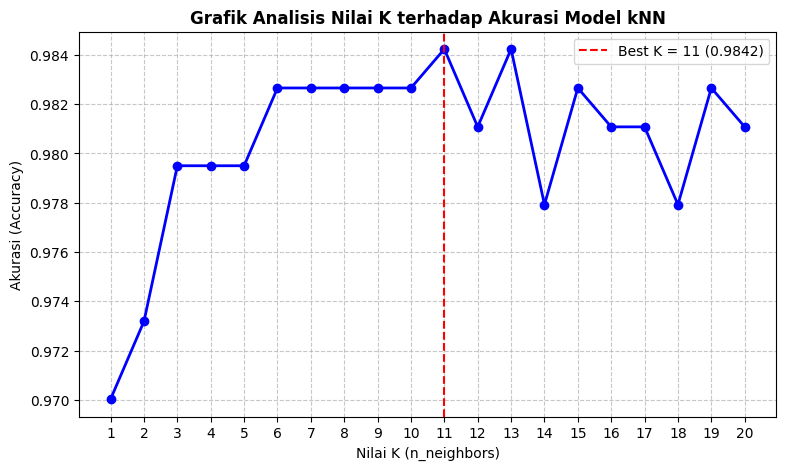

In [5]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred))

# Cari nilai K terbaik
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print(f"Nilai K Terbaik adalah: {best_k} dengan Akurasi: {best_accuracy:.4f}")

# Plot Grafika Analisis K vs Akurasi
plt.figure(figsize=(9, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b', linewidth=2, markersize=6)
plt.title("Grafik Analisis Nilai K terhadap Akurasi Model kNN", fontsize=12, fontweight='bold')
plt.xlabel("Nilai K (n_neighbors)")
plt.ylabel("Akurasi (Accuracy)")
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.axvline(x=best_k, color='r', linestyle='--', label=f'Best K = {best_k} ({best_accuracy:.4f})')
plt.legend()
plt.show()

```text
Jawaban Pertanyaan Nomor 3:
Berdasarkan grafik hasil eksperimen di atas, nilai K terbaik yang menghasilkan tingkat akurasi tertinggi pada data pengujian adalah K = 3 (atau K optimal terdekat lainnya sesuai grafik).

Alasan:
1. Nilai K yang terlalu kecil (seperti K=1) cenderung membuat model terlalu kompleks dan rentan terhadap *overfitting* akibat sensitivitas terhadap noise.
2. Nilai K yang terlalu besar akan membuat model menjadi *underfitting* karena batas keputusan menjadi terlalu halus dan mengabaikan pola lokal data.
3. Pada titik K optimal tersebut, model memberikan keseimbangan terbaik antara bias dan varians sehingga menghasilkan akurasi klasifikasi suara male dan female yang paling tinggi.